#PROYECTO CÁLCULO CIENTIFICO #1

Por:


*   Arturo Millán
*   Franyer Perez



##CARGA DE IMÁGENES

Para cargar las imágenes correspondientes para poder realizar el proyecto primero necesitamos una fuente fiable donde almacenar estas. En este caso escogimos google drive como herramienta para almacenar la imagen. Tomamos un enfoque en el cual sepuede cargar cualquier imagen de cualquier tamaño, solo se debe sustituir el link de dicha imagen en la siguiente seccion de código:

In [1]:

import re
import io
import requests
import matplotlib.pyplot as plt
from PIL import Image

#Cambie esta URL por una imagen con una de acceso publico de su preferencia:
url_publica_drive = 'https://drive.google.com/file/d/1FgnTzf5QK67a48X1KaDWTrB-ZQcb9-u-/view?usp=sharing'

#Aqui dejare mas imagenes que pueden probar (solo copie el enlace y peguelo arriba):
# Muro Ciencias UCV : 'https://drive.google.com/file/d/1poTIJoUMsAWqTA0uFvRMUQOjIrN6dDbG/view?usp=sharing'
#Premios SuperCodebros facultad de Ciencias UCV : 'https://drive.google.com/file/d/1eDfK7MLRhAXe8EHCfmrVnXQtGTGKyNQJ/view?usp=sharing'
#Dibujo Pasillo UCV : 'https://drive.google.com/file/d/1VsJl4_GGJJ_AhppxWWwq5nhafdUI3KlI/view?usp=sharing'
#Leyndell Ciudad Capital Elden Ring: 'https://drive.google.com/file/d/1FgnTzf5QK67a48X1KaDWTrB-ZQcb9-u-/view?usp=sharing'
#Inazuma Ciudad Genshin Impact: 'https://drive.google.com/file/d/1dyN8ut20FlGLetPoa8vQTbzU-w2_GUjF/view?usp=sharing'
#Gato baja resolucion de Google: 'https://drive.google.com/file/d/1U93IXTjXFIQf2hgEFIHWDf_cmBopekRz/view?usp=drive_link'


###Transformación a carga directa

Mediante expresiones regulares tomamos unicamente la parte luego de /d/ y seguarda en url_descarga_directa

In [2]:
def cargar_imagen_desde_drive_publico(url):
    match = re.search(r'/d/([a-zA-Z0-9-_]+)', url)

    if not match:
        print("Error: No se pudo identificar un ID válido en el enlace de Google Drive.")
        print("Asegúrate de copiar el enlace completo de la opción 'Compartir'.")
        return None

    file_id = match.group(1)

    url_descarga_directa = f'https://docs.google.com/uc?export=download&id={file_id}' #este url tiene el formato de descarga de drive, solo toma la parte necesaria y sustituye aqui

###Funcion de Carga de Imagen

Una vez se tiene la url, esta misma es validada,encaso contrario se indica cual es el error.

Nota: si encontro un error recuerde copiar el enlace completo de compartir, no elimine nada las expresiones regulares ya  realizan esa tarea.

In [3]:
def cargar_imagen_desde_drive_publico(url):
    match = re.search(r'/d/([a-zA-Z0-9-_]+)', url)

    if not match:
        print("Error: No se pudo identificar un ID válido en el enlace de Google Drive.")
        print("Asegúrate de copiar el enlace completo de la opción 'Compartir'.")
        return None

    file_id = match.group(1)

    url_descarga_directa = f'https://docs.google.com/uc?export=download&id={file_id}'

    try:
        respuesta = requests.get(url_descarga_directa)
        respuesta.raise_for_status()

        imagen = Image.open(io.BytesIO(respuesta.content))
        return imagen

    except Exception as e:
        print("Error al descargar la imagen. Verifica que:")
        print("1. El enlace sea correcto.")
        print("2. El archivo en Drive esté configurado como 'Cualquier persona con el enlace puede ver'.")
        print(f"\nDetalles del error: {e}")
        return None


##Visualización de especificaciones de la imagen cargada

Una vez cargada la imagen nos interesara conocer su formato, sus dimensiones, su modo y visualizar el tipo deimagen cargada.

Nota: Asegurese que la imagen cargada posea el modo RGB, en caso contrario, no podrá seguir continuando el programa.

Se Cargo la imagen Con las siguientes características:
Formato original: JPEG
Dimensiones: 640 x 1280 píxeles
Modo: RGB


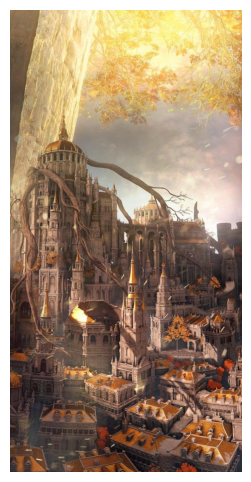

In [4]:
imagen = cargar_imagen_desde_drive_publico(url_publica_drive)
if imagen:
    print(
        f"Se Cargo la imagen Con las siguientes características:\n"
        f"Formato original: {imagen.format}\n"
        f"Dimensiones: {imagen.size[0]} x {imagen.size[1]} píxeles\n"
        f"Modo: {imagen.mode}"
    )


    plt.figure(figsize=(8, 6))
    plt.imshow(imagen)
    plt.axis('off')
    plt.show()

##Descomponer la imagen en RGB

Para poder implementar algun tipo de algoritmo matemático a esta imagen es necesario descomponerla en sus distintos canales de color, y asignar una matriz a cada uno de estos:

In [5]:
import numpy as np
import matplotlib.pyplot as plt

matriz_imagen = np.array(imagen) #se convierte la imagen en un arreglo de Numpy
alto, ancho, canales = matriz_imagen.shape #se muestra la forma de dicha matriz
print(f"Dimensiones de la matriz de la imagen: {alto} filas (alto) x {ancho} columnas (ancho) x {canales} canales (RGB)")

Dimensiones de la matriz de la imagen: 1280 filas (alto) x 640 columnas (ancho) x 3 canales (RGB)


###Separación y visualización de cada canal porseparado

En este paso se separa la imagenen sus respectivos canales de color que como vimos en el .shape anterior se encontraban en la ultima parte de dicho arreglo.


(np.float64(-0.5), np.float64(639.5), np.float64(1279.5), np.float64(-0.5))

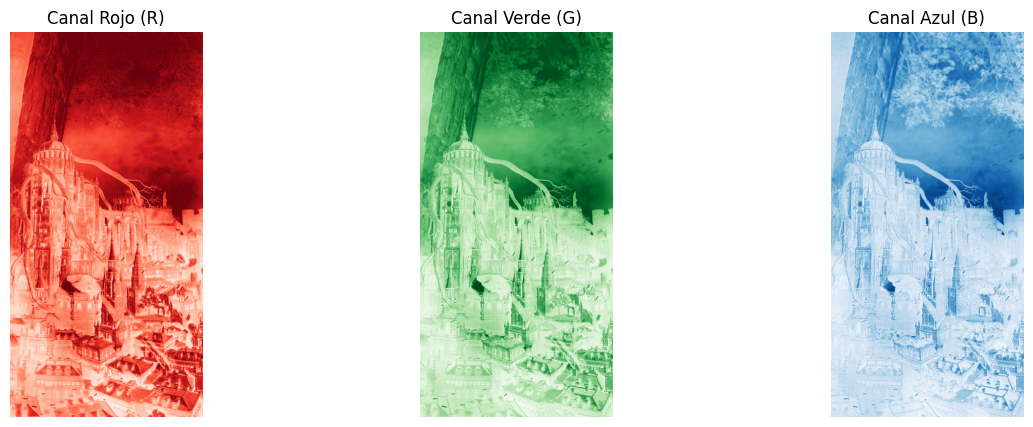

In [6]:
canal_R = matriz_imagen[:, :, 0]
canal_G = matriz_imagen[:, :, 1]
canal_B = matriz_imagen[:, :, 2]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(canal_R, cmap='Reds')
axes[0].set_title('Canal Rojo (R)')
axes[0].axis('off')

axes[1].imshow(canal_G, cmap='Greens')
axes[1].set_title('Canal Verde (G)')
axes[1].axis('off')

axes[2].imshow(canal_B, cmap='Blues')
axes[2].set_title('Canal Azul (B)')
axes[2].axis('off')

##Compresion de la imagen

Para comprimir la imagen de forma mas efectiva se aplicara PCA a una matriz decompuesta por SVD, para esto se debe:


*   Restar la media a los datos para centralizarlos
*   Aplicar SVD a la matriz centralizada
*   Obtener los componentes y la varianza de la matriz.

NOTA: Comprimir usando PCA ocupa mas espacio que solo usando SVD ya que se guarda la media, sin embargo es mas preciso al representar la imagen justamente al añadir esta media al reconstruir la matriz. (Esto lo sabemos porque al realizar el proyecto probamos una comparativa).



In [7]:
k_comp = [5, 20, 50, 100, 200]

def comprimir_canal_pca(canal):
    # se centran los datos calculando las medias de las filas
    mu = np.mean(canal, axis=1, keepdims=True)
    canal_centrado = canal - mu

    # SVD sobre la matriz centrada
    # En PCA, los autovectores de la covarianza son los vectores V de este SVD
    U, s, Vt = np.linalg.svd(canal_centrado, full_matrices=False)

    # autovalores (s^2 / (n-1)) para el error
    autovalores = (s**2) / (canal.shape[1] - 1)

    return {
        'U': U, 's': s, 'Vt': Vt,
        'mu': mu, 'autovalores': autovalores
    }

###Curva de error Real vs k Componentes PCA

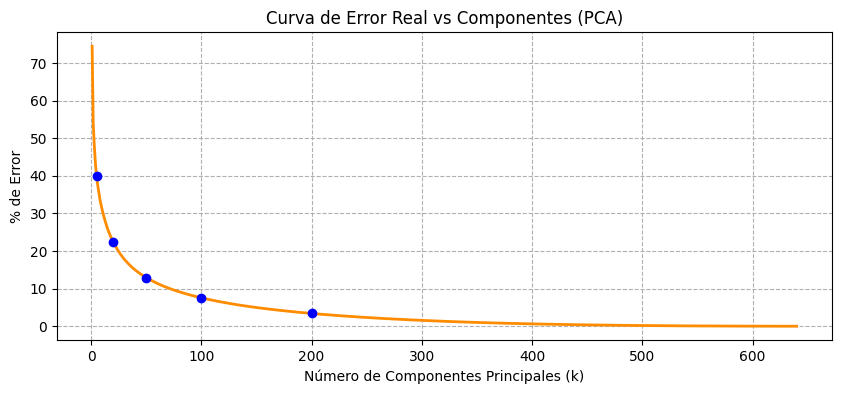

In [8]:
res_R = comprimir_canal_pca(canal_R)
res_G = comprimir_canal_pca(canal_G)
res_B = comprimir_canal_pca(canal_B)
# Se comprimen todos los canales

#El errorreal acumuladose calcula apartir del canal verde se puede usar cualquiera como referencia
vals = res_G['autovalores']
varianza_expl = np.cumsum(vals) / np.sum(vals)
error_acumulado_pca = 100 * (1 - varianza_expl)

# Gráfica de Curva de Error
plt.figure(figsize=(10, 4))
plt.plot(range(1, len(error_acumulado_pca) + 1), error_acumulado_pca, color='darkorange', lw=2)
plt.title('Curva de Error Real vs Componentes (PCA)')
plt.xlabel('Número de Componentes Principales (k)')
plt.ylabel('% de Error')
plt.grid(True, linestyle='--')

# Marcar los puntos k elegidos en la gráfica
for k in k_comp:
    if k <= len(error_acumulado_pca):
        plt.scatter(k, error_acumulado_pca[k-1], color='blue', zorder=5)
plt.show()

###Reeconstruccion de las Imagenes y comparación con la orginal

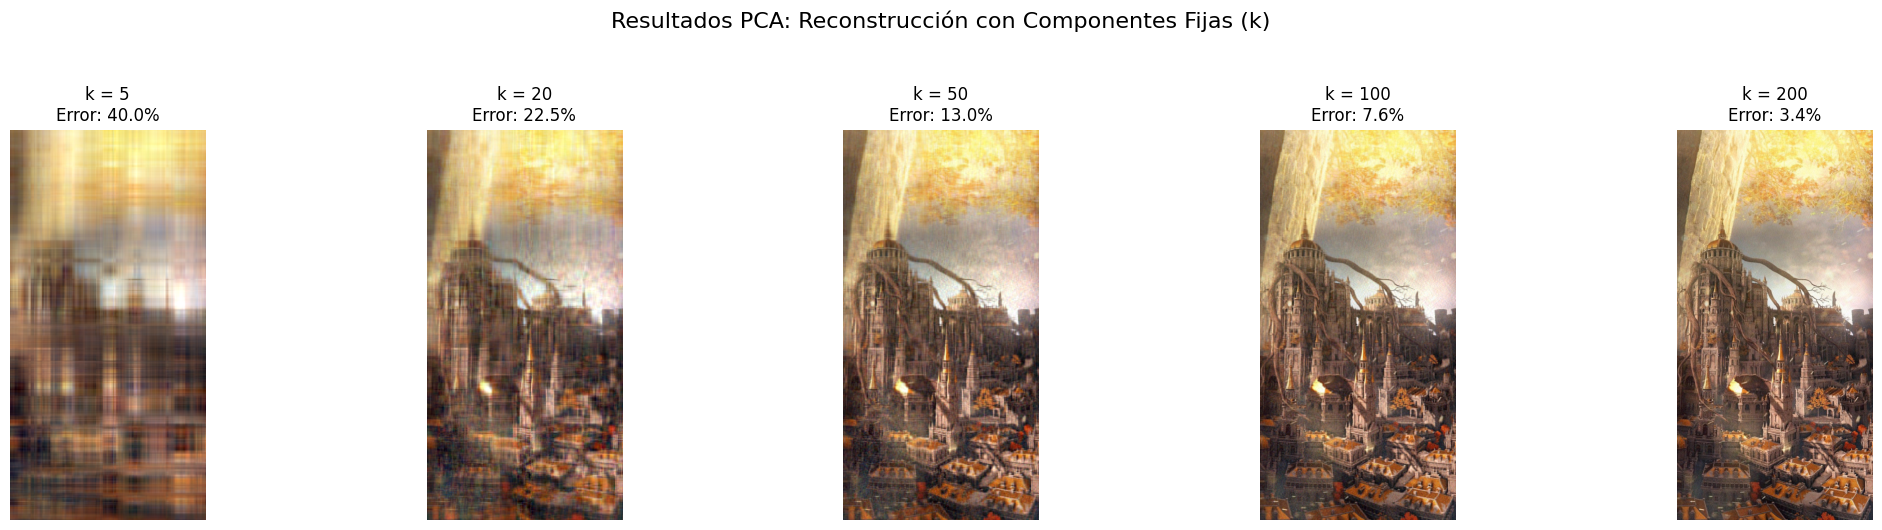

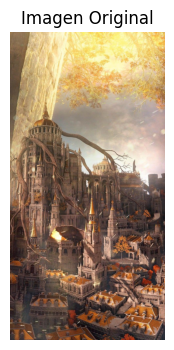

In [9]:



# Se reconstruyenlas imagenes tomando k componentes
def reconstruir_img(datos, k):
    # Aseguramos que k no exceda el tamaño de la imagen
    k_limite = min(k, datos['s'].shape[0])

    # Proceso inverso:
    # Se toma top k componentes: (U_k * Sigma_k * Vt_k)
    reconstruccion_centrada = np.dot(datos['U'][:, :k_limite],
                                     np.dot(np.diag(datos['s'][:k_limite]),
                                            datos['Vt'][:k_limite, :]))

    # Se suma la media, o descentralizar la imagen
    return reconstruccion_centrada + datos['mu']

imagenes_pca_final = []
errores_finales = []

for k in k_comp:
    # Reconstruimos cada canal
    r_rec = reconstruir_img(res_R, k)
    g_rec = reconstruir_img(res_G, k)
    b_rec = reconstruir_img(res_B, k)

    # Se mezclan
    img_rgb = np.stack([r_rec, g_rec, b_rec], axis=2)
    img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)
    imagenes_pca_final.append(img_rgb)

    # Registrar error (si k existe en la matriz)
    idx = min(k-1, len(error_acumulado_pca)-1)
    errores_finales.append(error_acumulado_pca[idx])

# Mostrar Galería de Resultados
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
fig.suptitle('Resultados PCA: Reconstrucción con Componentes Fijas (k)', fontsize=16, y=1.05)

for i in range(5):
    axes[i].imshow(imagenes_pca_final[i])
    axes[i].set_title(f"k = {k_comp[i]}\nError: {errores_finales[i]:.1f}%")
    axes[i].axis('off')

plt.tight_layout()
plt.figure(figsize=(5, 4))
plt.imshow(imagen)
plt.axis('off')
plt.title('Imagen Original')
plt.show()

###Energia, Error y tasa de compresion

   ANÁLISIS DE RENDIMIENTO PCA (Imagen de 1280x640 píxeles)
k     | Energía (Var) %  | Error Relativo % | Tasa Compresión (CR)
5     | 60.00            | 19.17            | 75.29               x
20    | 77.47            | 14.39            | 20.65               x
50    | 87.04            | 10.91            | 8.42                x
100   | 92.44            | 8.34             | 4.24                x
200   | 96.60            | 5.59             | 2.13                x


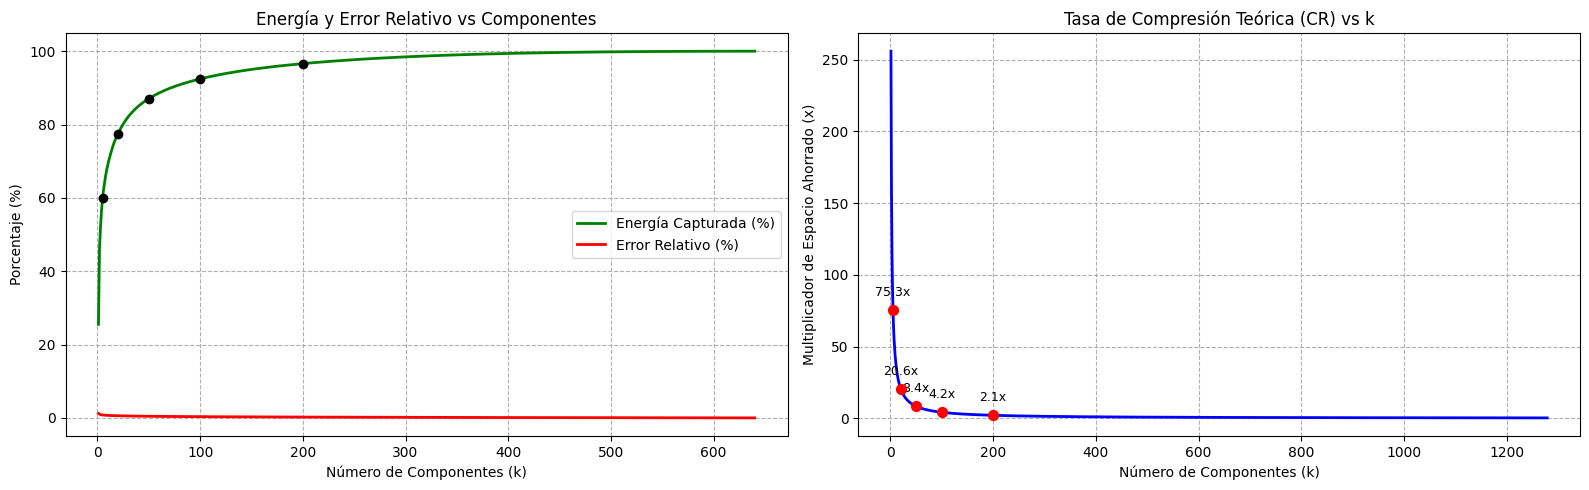

In [10]:


# Se toma el canal verde pero realmente se puede tomar cualquiera
m, n = canal_G.shape

# Listas para almacenar las métricas de cada k
energias = []
errores_relativos = []
tasas_compresion = []

print(f"   ANÁLISIS DE RENDIMIENTO PCA (Imagen de {m}x{n} píxeles)")
print(f"{'k':<5} | {'Energía (Var) %':<16} | {'Error Relativo %':<16} | {'Tasa Compresión (CR)':<20}")

# Calculamos las métricas para cada k en k_comp
for i, k in enumerate(k_comp):
    # Energia se expresa enporcentaje
    energia_k = varianza_expl[min(k-1, len(varianza_expl)-1)] * 100
    energias.append(energia_k)

    # ||Canal - Canal_Reconstruido|| / ||Canal||
    canal_g_rec = reconstruir_img(res_G, k)
    norma_residuo = np.linalg.norm(canal_G - canal_g_rec, 'fro')
    norma_original = np.linalg.norm(canal_G, 'fro')
    error_rel_k = (norma_residuo / norma_original) * 100
    errores_relativos.append(error_rel_k)

    # Tasa de Compresión Teórica
    datos_originales = m * n
    datos_comprimidos = m + (n * k) + (m * k)
    cr_k = datos_originales / datos_comprimidos
    tasas_compresion.append(cr_k)

    print(f"{k:<5} | {energia_k:<16.2f} | {error_rel_k:<16.2f} | {cr_k:<20.2f}x")


fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfica 1: Energía vs Error Relativo
axes[0].plot(range(1, len(varianza_expl) + 1), varianza_expl * 100, color='green', label='Energía Capturada (%)', lw=2)
# El error relativo total de la curva se puede aproximar con la norma de los autovalores remanentes
error_curva_rel = 100 * (np.sqrt(np.cumsum(vals[::-1])[::-1]) / np.linalg.norm(canal_G))
# Ajustamos las dimensiones por seguridad numérica
error_curva_rel = error_curva_rel[:len(varianza_expl)]

axes[0].plot(range(1, len(error_curva_rel) + 1), error_curva_rel, color='red', label='Error Relativo (%)', lw=2)
axes[0].set_title('Energía y Error Relativo vs Componentes')
axes[0].set_xlabel('Número de Componentes (k)')
axes[0].set_ylabel('Porcentaje (%)')
axes[0].grid(True, linestyle='--')
axes[0].legend()

# Marcar los puntos evaluados
for k in k_comp:
    if k <= len(varianza_expl):
        axes[0].scatter(k, varianza_expl[k-1]*100, color='black', zorder=5)

# Gráfica 2: Tasa de Compresión Eficiente
k_eje = np.arange(1, m)
cr_eje = (m * n) / (m + (n * k_eje) + (m * k_eje))
axes[1].plot(k_eje, cr_eje, color='blue', lw=2, label='Curva de CR')
axes[1].set_title('Tasa de Compresión Teórica (CR) vs k')
axes[1].set_xlabel('Número de Componentes (k)')
axes[1].set_ylabel('Multiplicador de Espacio Ahorrado (x)')
axes[1].grid(True, linestyle='--')

# Marcar nuestros k específicos en la gráfica de CR
for k, cr in zip(k_comp, tasas_compresion):
    axes[1].scatter(k, cr, color='red', s=50, zorder=5)
    axes[1].annotate(f"{cr:.1f}x", (k, cr), textcoords="offset points", xytext=(0,10), ha='center', fontsize=9)

plt.tight_layout()
plt.show()